**Docente:** MSc. Juan Carlos Gonzalez

# Segmentación de clientes: caso Depratti

**Práctica: PCA y K-Means**

**Nombre Estudiante:** 

Se trabajará con un dataset **sintético** de 600 clientes inspirado en el contexto comercial de Deprati (Ecuador). Los registros no corresponden a clientes reales.

**Ruta de trabajo:** objetivo empresarial → selección de variables → correlaciones → estandarización → PCA → K-Means → interpretación comercial.


## 1. Objetivo empresarial

El equipo de Marketing necesita identificar tipos de clientes según sus hábitos de compra. La empresa podría utilizar los grupos para proponer promociones o acciones de fidelización distintas.



### Descripción de las columnas del dataset

Cada fila representa a un cliente de la tienda y cada columna describe un aspecto de ese cliente.

| Columna | Significado para el negocio | Unidad |
| --- | --- | --- |
| `cliente_id` | Código que identifica a cada cliente. No describe su comportamiento de compra. | Código |
| `ciudad` | Ciudad del cliente. Permite analizar después cómo se distribuyen los grupos. | Texto |
| `edad` | Edad del cliente. Aporta información sobre su perfil demográfico. | Años |
| `antiguedad_meses` | Tiempo que lleva como cliente. Distingue a los clientes nuevos de los consolidados. | Meses |
| `compras_12m` | Número de compras del último año. Mide la frecuencia con la que compra. | Compras |
| `gasto_anual_usd` | Dinero gastado durante el año. Refleja el valor económico del cliente para la tienda. | USD |
| `ticket_promedio_usd` | Gasto promedio por compra. Muestra si realiza compras de valor alto o bajo. | USD |
| `descuento_promedio_pct` | Descuento promedio de sus compras. Ayuda a identificar su sensibilidad a las promociones. | % |
| `porcentaje_compras_online` | Proporción de compras en línea. Indica su preferencia por el canal digital. | % |
| `porcentaje_moda` | Parte de sus compras que corresponde a la categoría moda. | % |
| `porcentaje_hogar` | Parte de sus compras que corresponde a la categoría hogar. | % |
| `porcentaje_tecnologia` | Parte de sus compras que corresponde a la categoría tecnología. | % |
| `porcentaje_belleza` | Parte de sus compras que corresponde a la categoría belleza. | % |
| `devoluciones_12m` | Número de devoluciones del último año. Puede señalar insatisfacción y genera costos operativos. | Devoluciones |
| `visitas_web_mes` | Visitas mensuales al sitio web. Refleja su interés e interacción digital. | Visitas |
| `dias_desde_ultima_compra` | Días de inactividad. Un valor alto puede indicar riesgo de que deje de comprar. | Días |

**Relaciones observadas en las primeras filas del dataset:** el ticket promedio equivale al gasto anual dividido para el número de compras, y los cuatro porcentajes por categoría suman 100 %.

## 2. Cargar el dataset

El archivo `deprati_clientes_sinteticos_600.csv` debe estar en la misma carpeta que este notebook.

In [5]:
# Librerías para manejar la tabla de datos (pandas) y para graficar (matplotlib, seaborn).
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Herramientas de scikit-learn para el flujo de la práctica:
# StandardScaler (misma escala) -> PCA (menos dimensiones) -> KMeans (grupos).
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Carga el dataset. Cada fila es un cliente y cada columna una característica.
df = pd.read_csv('deprati_clientes_sinteticos_600.csv')


print(df.shape)

(600, 16)


## 3. Seleccionar 8 características

No seleccionamos las primeras ocho columnas por su posición. Elegimos variables que tienen relación con el objetivo de Marketing(para hacer esto bien, hay que entender el negocio):

| Característica              | ¿Qué representa?                  |
| --------------------------- | --------------------------------- |
| `gasto_anual_usd`           | Dinero gastado durante el año     |
| `compras_12m`               | Número de compras del último año  |
| `ticket_promedio_usd`       | Gasto promedio por compra         |
| `descuento_promedio_pct`    | Descuento promedio de sus compras |
| `porcentaje_compras_online` | Proporción de compras en línea    |
| `devoluciones_12m`          | Número de devoluciones            |
| `visitas_web_mes`           | Visitas mensuales al sitio web    |
| `dias_desde_ultima_compra`  | Días de inactividad               |

Se excluyen cliente_id y ciudad: no describen el comportamiento de compra. Otras columnas podrían elegirse en un análisis diferente.

**Observación:** gasto anual, número de compras y ticket promedio están relacionados; veremos esa relación en la matriz de correlaciones.


In [11]:
columnas = [
    'gasto_anual_usd',
    'compras_12m',
    'ticket_promedio_usd',
    'descuento_promedio_pct',
    'porcentaje_compras_online',
    'devoluciones_12m',
    'visitas_web_mes',
    'dias_desde_ultima_compra'
]

# X sera la matriz de trabajo: conservar todas las filas y solo las 8 columnas seleccionadas
X = df[columnas]
# Se espera(600, 8): 600 observaciones y 8 dimenciones
print(X.shape)
X.head()

(600, 8)


,gasto_anual_usd,compras_12m,ticket_promedio_usd,descuento_promedio_pct,porcentaje_compras_online,devoluciones_12m,visitas_web_mes,dias_desde_ultima_compra
0,1289.43,9,143.27,24.2,13.0,0,12,2
1,1619.64,11,147.24,8.4,15.8,1,11,50
2,1247.00,5,249.40,7.0,17.1,0,5,102
3,67.84,1,67.84,28.5,15.5,0,6,112
4,959.68,4,239.92,2.9,62.2,0,16,4


Antes de continuar, revisamos si existen datos faltantes y observamos estadísticas básicas.


In [12]:
# Contar los valores faltantes por columna
#PCA y KMEANS no acpetan valores nulos
print(X.isnull().sum())
#Sacar estadisticas basicas, medias y desviaciones
X.describe().round(2)

gasto_anual_usd              0
compras_12m                  0
ticket_promedio_usd          0
descuento_promedio_pct       0
porcentaje_compras_online    0
devoluciones_12m             0
visitas_web_mes              0
dias_desde_ultima_compra     0
dtype: int64


,gasto_anual_usd,compras_12m,ticket_promedio_usd,descuento_promedio_pct,porcentaje_compras_online,devoluciones_12m,visitas_web_mes,dias_desde_ultima_compra
count,600.00,600.00,600.00,600.00,600.00,600.00,600.00,600.00
mean,836.40,4.38,189.14,14.98,34.62,0.28,10.71,66.12
std,640.09,2.81,104.13,9.83,26.83,0.55,6.26,74.53
min,36.58,1.00,36.58,0.00,0.00,0.00,0.00,1.00
25%,252.75,2.00,99.20,7.30,12.28,0.00,6.00,14.00
50%,785.63,4.00,172.86,13.00,28.15,0.00,10.00,38.00
75%,1220.62,6.00,261.80,21.82,54.85,0.00,16.00,94.00
max,3235.84,14.00,479.61,40.70,100.00,4.00,27.00,360.00


## 4. Analizar correlaciones

La correlación ayuda a observar si dos características tienden a aumentar o disminuir juntas. Sus valores van de -1 a 1:

- Cercano a **1**: relación positiva fuerte.
- Cercano a **-1**: relación negativa fuerte.
- Cercano a **0**: relación lineal débil.

Las correlaciones permiten revisar que variables comparten información antes de resumirlas con componentes en PCA


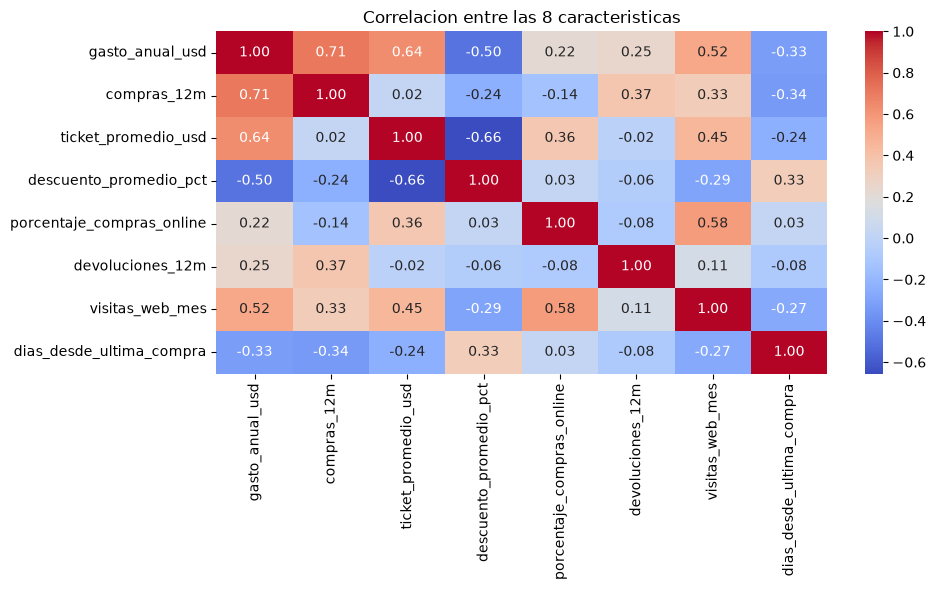

In [14]:
plt.figure(figsize=(10,6))
# X.corr() calcula la correlacion entre cada par de variables (1 a -1)
#annot = True escribe el valor en cada celda

sns.heatmap(X.corr(), annot = True, fmt = '.2f', cmap= 'coolwarm')
plt.title("Correlacion entre las 8 caracteristicas")
plt.tight_layout()
plt.show()

**¿Cuáles son las dos variables con mayor correlación positiva? ¿Tendría sentido que estén relacionadas en una tienda?**


## 5. Estandarizar las características

Las variables tienen unidades diferentes: dólares, porcentajes, visitas y días. Si usamos directamente esos valores, las variables con números más grandes podrían dominar el cálculo de distancias.

`StandardScaler` transforma cada característica para que tenga aproximadamente media 0 y desviación estándar 1.


In [ ]:
#Kmeans usa distancia euclidiana y PCA prioriza las direcciones con mas varianza
escalador = StandardScaler()
#fit calcular la media y la desviacion estandar de cada columna
#transform aplizar z = (valor-media)/ desviacion on estado dejo media en 0 y desviacion 1
#El resultado es unarreglo de Numpy, ya no un dataset
X_escalado = escalador.fit_transform(X)

#Comparar 3 clientes y columnas antes y despues de escalar
print("Antes de estandarizar:")
print(X.iloc[:3,:3])

print("Despues de estandarizar:")
print(X_escalado[:3,:3].round(2))
#Es decir ese cliente gasta 1.22 desviaciones por encima del promedio y compra
#2.35 desviaciones por encima del promedio

Antes de estandarizar:
   gasto_anual_usd  compras_12m  ticket_promedio_usd
0          1289.43            9               143.27
1          1619.64           11               147.24
2          1247.00            5               249.40
Despues de estandarizar:
[[ 0.71  1.65 -0.44]
 [ 1.22  2.36 -0.4 ]
 [ 0.64  0.22  0.58]]


Cada valor individual puede ser mayor que 1 o menor que -1, lo que se cumple es que al promediar toda la columna da aproximadamente 0 y su dispersión da 1, porque se utilizo StandarScaler

## 6. Aplicar PCA: de 8 características a 2 componentes

En esta práctica configuramos PCA para generar **dos componentes nuevos**, aunque podría generar hasta ocho. Estos componentes combinan la información de las ocho características; PCA no se limita a escoger dos columnas del dataset.

Primero calcularemos los dos componentes y luego verificaremos qué porcentaje de la varianza total representan. **Con dos componentes se explica el 59.44 % de la varianza total** (CP1: 39.48 % y CP2: 19.96 %).


In [19]:
#n_component = 2 conservar solo los primeros componentes principales
#CP1 capturar la mayor variabilidad posible, CP2 la mayor variabilidad restante
pca = PCA(n_components=2)
#fit encontrar las direcciones de esos componentes y transform los proyecta a cada cliente
X_pca = pca.fit_transform(X_escalado)

#PCA cambias las columnas, no elimina las filas de clientes
#se pasa de (600, 8) a (600, 2)
print('Forma inicial: ', X_escalado.shape)
print('Forma despues de PCA: ', X_pca.shape)


Forma inicial:  (600, 8)
Forma despues de PCA:  (600, 2)


Varianza explciada CP1:  39.48 %
Varianza explciada CP2:  19.96 %
Varianza explciada total:  59.44 %


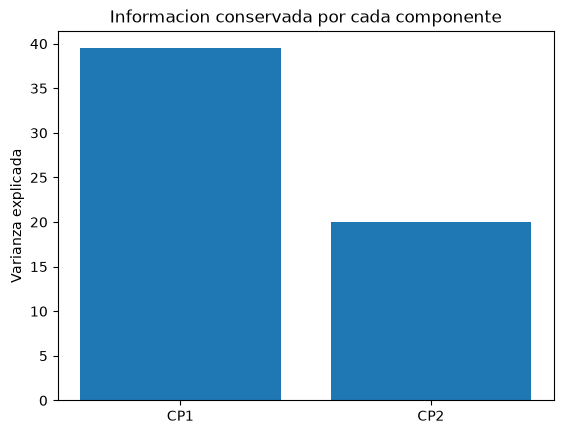

In [21]:
#expalined_variance_ratio de la proporcion de variables que explica cada componente
varianza = pca.explained_variance_ratio_*100

print('Varianza explciada CP1: ', round(varianza[0],2), '%')
print('Varianza explciada CP2: ', round(varianza[1],2), '%')
print('Varianza explciada total: ', round(varianza.sum(),2), '%')

#Grafico de barras PCA
plt.bar(['CP1', 'CP2'], varianza)
plt.ylabel("Varianza explicada")
plt.title('Informacion conservada por cada componente')
plt.show()

In [26]:
pca_completo = PCA() 
pca_completo.fit(X_escalado) 
varianza_8 = pca_completo.explained_variance_ratio_ * 100 

tabla_varianza = pd.DataFrame({ 
    'Componente': [f'CP{i}' for i in range(1, 9)], 
    'Varianza explicada (%)': varianza_8.round(2), 
    'Varianza acumulada (%)': varianza_8.cumsum().round(2) 
})

tabla_varianza

,Componente,Varianza explicada (%),Varianza acumulada (%)
0,CP1,39.48,39.48
1,CP2,19.96,59.44
2,CP3,14.29,73.73
3,CP4,10.16,83.89
4,CP5,8.11,92.00
5,CP6,4.68,96.68
6,CP7,2.83,99.51
7,CP8,0.49,100.00


**Importante:** usar solo dos componentes facilita el gráfico, pero puede perder información. Si la varianza explicada total es baja, los grupos obtenidos podrían ser diferentes de los que se encontrarían usando más componentes.


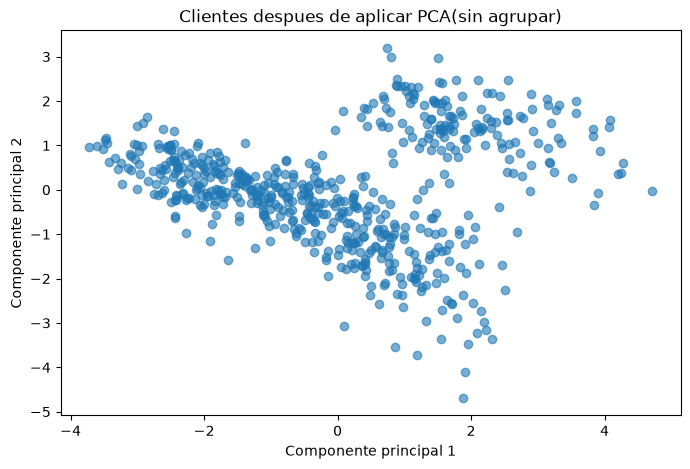

In [ ]:
#Cada punto es un cliente representado con sus dos componentes, todavia no existen grupos
plt.figure(figsize=(8,5))
#toma todas las filas de CP1 y el segundo elige, todas las de CP2
#ALPHA DA transparencia para distinguir puntos que esten sobrepuestos
plt.scatter(X_pca[:,0], X_pca[:,1], alpha=0.6)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Clientes despues de aplicar PCA(sin agrupar)")
plt.show()

#No hay umbral o regla para determinar la cantidad de componentes
#Lo ideal sera siempre tener la mayor cantidad de representacion 

## 7. K-Means: elegir la cantidad de grupos

K-Means agrupa clientes según la distancia entre sus posiciones y los centroides. En cada iteración asigna puntos a su centroide más cercano y actualiza los centroides.

Para escoger un valor inicial de `k` utilizaremos el **método del codo**. Buscaremos dónde la disminución de la inercia comienza a ser menos marcada. Este método orienta la decisión, pero no siempre ofrece un valor único.


c:\Users\FUNDAMENTOS IA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\FUNDAMENTOS IA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\FUNDAMENTOS IA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\FUNDAMENTOS IA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is k

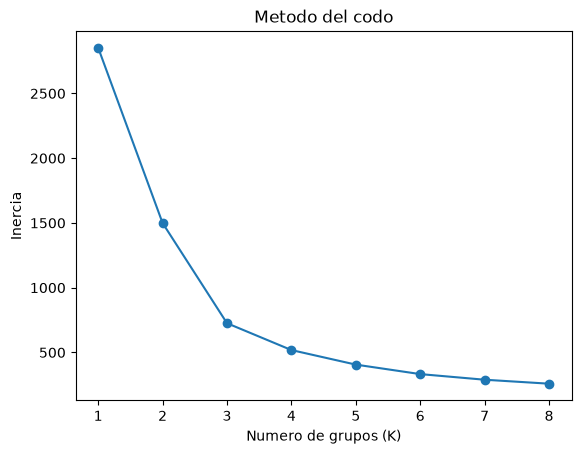

In [29]:
inercias = []

for k in range(1,9):
    #random_state fija el azar y obtener mismo resultado
    #n_init = 10 para repetir el algoritmo con 10 inicios distintos y conservar el de menor inercia
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    #Se entro con los 2 componentes de PCA
    modelo.fit(X_pca)
    inercias.append(modelo.inertia_)

#La inercia baja al aumentar k, Se busca el punto donde agregar mas grupos ya no aporta
plt.plot(range(1,9), inercias, marker = 'o')
plt.xlabel('Numero de grupos (K)')
plt.ylabel('Inercia')
plt.title('Metodo del codo')
plt.xticks(range(1,9))
plt.show()

**Para discutir:** ¿qué valor de `k` parece razonable según el gráfico? En el ejemplo siguiente usaremos **4 grupos** como punto de partida; se puede modificar según la interpretación del codo y las necesidades del negocio.


## 8. Ejecutar K-Means

Entrenamos K-Means sobre los **dos componentes de PCA**. Cada cliente recibe un número de grupo: 0, 1, 2 o 3. Esos números son identificadores, no categorías comerciales.


In [31]:
#Modelo final con k = 4
#1. Ubiica centroides iniciales
#2. Asigna cada cliente al centroide mas cercano
#3. Recalcula cada centro como el promedio de los puntos de su grupo
#4. Converge cuando los centroides dejen de moverse o sus cambios sean insignificantes 
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
#fit predict entrenar el modelo y devolver el numero de grupo de cada cliente
grupos = kmeans.fit_predict(X_pca)

#Cantidad de clientes por grupo
print(pd.Series(grupos).value_counts().sort_index())

0    150
1    160
2    130
3    160
Name: count, dtype: int64


c:\Users\FUNDAMENTOS IA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


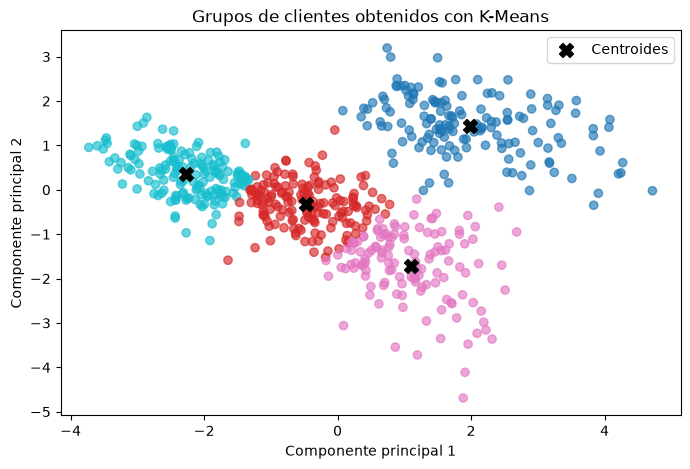

In [32]:
plt.figure(figsize=(8,5))
plt.scatter(X_pca[:,0], X_pca[:,1], c= grupos, cmap = 'tab10', alpha= 0.65)

plt.scatter(kmeans.cluster_centers_[:,0],
            kmeans.cluster_centers_[:,1],
            c= 'black', marker = 'X', s=100, label = "Centroides")

plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Grupos de clientes obtenidos con K-Means")
plt.legend()
plt.show()

## 9. Interpretación comercial

Para comprender qué significa cada grupo, regresamos a las **variables originales en sus unidades reales** (dólares, días, porcentajes). No basta con mirar las coordenadas de PCA.

Calculamos los promedios de las ocho características por grupo.


In [33]:
resultado = df.copy()
resultado['grupo'] = grupos

#Promedio de las variables originales por grupo: estan en USD, dias y porcentajes
resumen = resultado.groupby('grupo')[columnas].mean().round(2)
resumen

,gasto_anual_usd,compras_12m,ticket_promedio_usd,descuento_promedio_pct,porcentaje_compras_online,devoluciones_12m,visitas_web_mes,dias_desde_ultima_compra
grupo,,,,,,,,
0,1355.51,4.19,320.27,8.77,71.21,0.21,18.37,47.76
1,654.37,3.63,196.59,11.63,14.01,0.13,6.71,53.38
2,1293.66,8.38,158.81,12.07,16.19,0.75,12.37,24.08
3,160.22,2.08,83.40,26.51,35.89,0.11,6.17,130.24


Comparamos tres indicadores especialmente fáciles de interpretar: gasto, frecuencia de compra y días desde la última compra.


In [34]:
resumen[['gasto_anual_usd', 'compras_12m', 'dias_desde_ultima_compra']]

,gasto_anual_usd,compras_12m,dias_desde_ultima_compra
grupo,,,
0,1355.51,4.19,47.76
1,654.37,3.63,53.38
2,1293.66,8.38,24.08
3,160.22,2.08,130.24


In [ ]:
#Que nombre le pondrian, a cada grupo, suponiendo que ya deben exponer los
#  resultados al lider tecnico.

# 0 = 
# 1 =
# 2 = 
# 3 = 

Que nombre le pondrian, a cada grupo, suponiendo que ya deben exponer los resultados al lider tecnico.

0 = Cliente recurrente
1 = Cliente poco recurrente
2 = Cliente muy recurrente
3 = Cliente muy poco recurrente

**Docente:** MSc. Juan Carlos Gonzalez